In [1]:
from helpers import evaluation as ev
from datasets import load_dataset
from helpers import embedding as eb

import pandas as pd
import matplotlib.pyplot as plt
from google import genai

from dotenv import load_dotenv
from pathlib import Path
import os

try:
    load_dotenv()
    API_KEY = os.getenv("GOOGLE_API_KEY")
except Exception as e:
    print(f"Error loading environment variable(s): {e}")

PROJECT_ROOT = Path.cwd().parent
CHROMA_DIR = PROJECT_ROOT / "Data" / "chroma"
eval_client = genai.Client(api_key=API_KEY)
rows = [dict(r) for r in load_dataset("PatronusAI/financebench", split="train")]
collection = eb.get_collection(CHROMA_DIR)

## Retrieval evaluation

This test measures whether the retriever finds the page of the filing that contains the evidence for a question. It does not involve the language model. Each of the 150 FinanceBench questions comes with gold evidence: the document and page where the answer is found.

**Procedure.** For each question, the question text is embedded and the 10 closest pieces (`k = 10`) are retrieved from the vector store. The result is the *rank* of the first retrieved piece that lies on a gold evidence page. If no piece in the top 10 lies on a gold page, the rank is empty and the question counts as a miss.

**Search scopes.** The same test is run five times with different metadata filters. The first three are *oracle* scopes: the filter is read from the dataset labels, which a real user query would not provide. The last two are *query-derived*: the filter is extracted from the question text alone by rule-based parsing (`helpers/query_parsing.py`).
- `none`: the whole collection is searched, with no filter.
- `company`: oracle. The search is restricted to the company of the question, as labelled in the dataset.
- `doc`: oracle. The search is restricted to the exact filing the question refers to. This assumes the filing is known, so it gives an upper bound on retrieval quality.
- `rules`: query-derived. The company is found in the question with an alias table, and used as a filter. If no company is recognised, the whole collection is searched.
- `rules_year`: query-derived. As `rules`, plus a filter on the filing year found in the question (`FY2022`, `2022`, `FY22`). The filing year and the one after it are accepted, because later filings repeat earlier figures.

**Metrics.**
- `n`: the number of questions evaluated (150).
- `recall@k`: the share of questions whose gold page appears within the top *k* results. For example, `recall@5 = 0.92` means that 92% of questions have the evidence page among the first five results. It is reported at k = 1, 3, 5 and 10.
- `mrr` (mean reciprocal rank): the average of 1/rank over all questions, counting a miss as 0. A first-place hit scores 1, second place 0.5, third place 0.33, and so on. It ranges from 0 to 1 and rewards placing the gold page higher, which recall@k does not capture.

A page counts as a hit only if both the document name and the page number match. A different page of the same filing does not count.

In [2]:
out = PROJECT_ROOT / "Data" / "eval"
out.mkdir(exist_ok=True)

summaries, all_results = [], {}
for scope in ev.ALL_SCOPES:
    s, r = ev.retrieval_eval(rows, collection, eval_client, scope=scope, k=10,
                             out_path=out / f"retrieval_{scope}.json")
    summaries.append(s); all_results[scope] = r
pd.DataFrame(summaries).set_index("scope").round(3)

,n,mrr,recall@1,recall@3,recall@5,recall@10
scope,,,,,,
none,150,0.580,0.427,0.700,0.780,0.873
company,150,0.622,0.460,0.753,0.860,0.920
doc,150,0.677,0.513,0.820,0.920,0.967
rules,150,0.621,0.460,0.753,0.853,0.913
rules_year,150,0.623,0.460,0.753,0.867,0.927
fusion,150,0.644,0.493,0.767,0.840,0.920


## Analysis of missed questions

A question is a miss when its gold page is not in the top 10 retrieved pieces (`rank` is empty). The first table lists the misses for the `doc` scope by filing. The chart after it compares all five scopes: each dot is a filing with at least one miss in that scope, and the number is the count of missed questions.

The purpose is to see whether failures are spread evenly or concentrated, for example in certain filings, in table-heavy questions, or in documents where section detection found no headings. Questions that are found but ranked below 3 are a separate case: the right page was retrieved but placed too low, which is a ranking problem rather than a coverage problem.

Note that a miss means only that the *labelled* evidence page was not retrieved. A question may still be answerable from another page that contains the same figure, so the miss count slightly understates how well the system can answer.

Two limits are to be remembereding when you read the numbers. With 150 questions, one question is about 0.7 points of recall, so small differences between scopes are weak evidence. And recall@k here depends on k, which is fixed at 10 in the test, so numbers from a different k aren't comparable.

In [3]:
res = pd.DataFrame(all_results["doc"])
miss = res[res["rank"].isna()]
print(len(miss))
miss.groupby("doc_name").size().sort_values(ascending=False).head(10)

5


doc_name
PFIZER_2021_10K        2
BOEING_2022_10K        1
JPMORGAN_2021Q1_10Q    1
JPMORGAN_2022_10K      1
dtype: int64

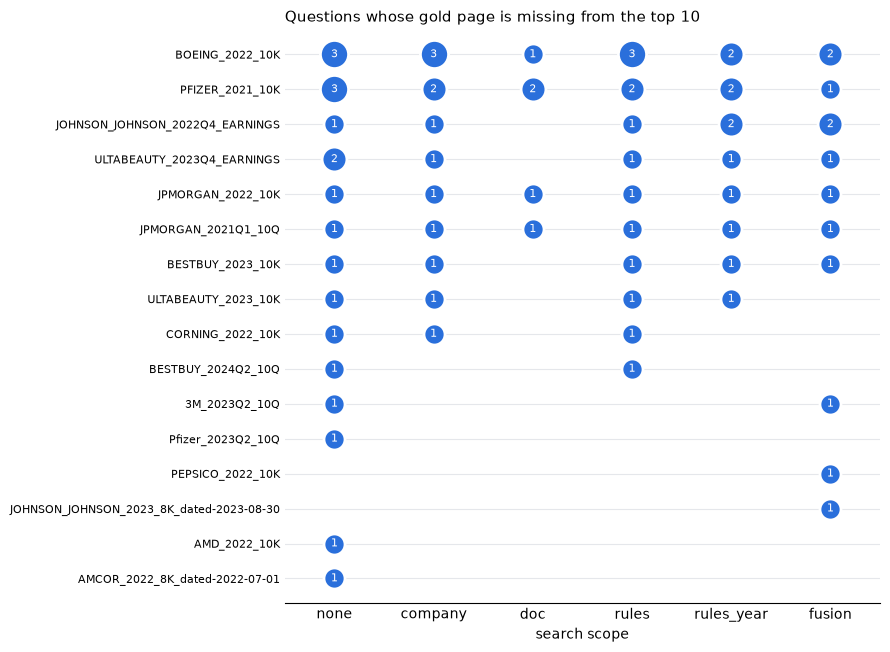

In [4]:
# one row per (scope, question): did the gold page fail to appear in the top 10?
df = pd.DataFrame(
    {"scope": scope, "doc_name": r["doc_name"], "missed": r["rank"] is None}
    for scope, results in all_results.items() for r in results
)

# misses per filing and scope; keep only filings with at least one miss
counts = (
    df[df["missed"]].groupby(["doc_name", "scope"]).size()
    .unstack(fill_value=0)
    .reindex(columns=list(ev.ALL_SCOPES), fill_value=0)
)
counts = counts.loc[counts.sum(axis=1).sort_values().index]   # worst filings at the top

fig, ax = plt.subplots(figsize=(9, 0.32 * len(counts) + 1.5))
for y, (doc, row) in enumerate(counts.iterrows()):
    for x, n in enumerate(row):
        if n:
            ax.scatter(x, y, s=140 + 90 * n, color="#2a6fdb", edgecolor="white", linewidth=2, zorder=3)
            ax.text(x, y, str(n), ha="center", va="center", color="white", fontsize=8, zorder=4)

ax.set_xticks(range(len(ev.ALL_SCOPES)), ev.ALL_SCOPES)
ax.set_yticks(range(len(counts)), counts.index, fontsize=8)
ax.set_xlim(-0.5, len(ev.ALL_SCOPES) - 0.5)
ax.set_ylim(-0.7, len(counts) - 0.3)
ax.grid(axis="y", color="#e5e7eb", zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.set_xlabel("search scope")
ax.set_title("Questions whose gold page is missing from the top 10", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## Answer evaluation

The retrieval evaluation above checks whether the right page is found. This section checks the end result: whether the answer written by the model is correct.

**Procedure.** The RAG system (`helpers/rag.py`) answers each of the 150 questions, using the query filter and `K = 10` pieces of context. Each answer is then compared with the gold answer of the dataset by a language model used as a judge, which returns a verdict (correct or not) and a one-sentence reason. Answers and verdicts are saved in `Data/eval/`, so an interrupted run resumes where it stopped and a rerun costs nothing.

**Trial first.** `LIMIT = 10` runs the first ten questions only. Set it to `None` for the full run (about 150 answers and 150 verdicts).

**Reading the results.**
- `accuracy`: the share of answers judged correct.
- `gold_in_context`: whether a gold evidence page was among the pieces given to the model. Accuracy is reported separately for the two cases. A wrong answer with the gold page present is a generation problem (reading the table, doing the arithmetic). A wrong answer without it is a retrieval problem.

**Limits of the judge.** The judge is a language model of the same family as the one that answers, and it can be strict or lenient on rounding and units. The verdict is a first estimate. The table of wrong answers at the end shows the reasons, and reading a sample of them is the way to check the judge.

In [5]:
LIMIT = 10          # None runs all 150 questions
USE_FUSION = False  # True also searches LLM rewrites of the question (one extra model call per question)

tag = "fusion" if USE_FUSION else "rules_year"
records = ev.answer_eval(rows, collection, eval_client, use_fusion=USE_FUSION,
                         out_path=out / f"answers_{tag}.json", limit=LIMIT)
print(f"{len(records)} questions answered")

answering:   0%|          | 0/10 [00:00<?, ?it/s]

10 questions answered


In [6]:
records = ev.judge_answers(records, eval_client, out_path=out / f"judged_{tag}.json")
ans = pd.DataFrame(records)
valid = ans[ans["correct"].notna()].astype({"correct": bool})
print(f"{len(valid)} judged, accuracy {valid['correct'].mean():.3f}")

judging:   0%|          | 0/10 [00:00<?, ?it/s]

10 judged, accuracy 0.700


In [7]:
by_type = valid.groupby("question_type")["correct"].agg(accuracy="mean", n="size")
by_context = valid.groupby("gold_in_context")["correct"].agg(accuracy="mean", n="size")
display(by_type.round(3), by_context.round(3))

,accuracy,n
question_type,,
domain-relevant,0.50,4
metrics-generated,0.75,4
novel-generated,1.00,2


,accuracy,n
gold_in_context,,
True,0.7,10


In [8]:
wrong = valid[~valid["correct"]]
pd.set_option("display.max_colwidth", 140)
wrong[["id", "gold_in_context", "gold_answer", "answer", "reason"]]

,id,gold_in_context,gold_answer,answer,reason
1,financebench_id_04672,True,$8.70,"Based on the Consolidated Balance Sheet in the provided context, the net property, plant, and equipment (Property, plant and equipment —...","The answer provides $8.738 billion (8,738 million), which differs from the reference answer of $8.70 billion."
2,financebench_id_00499,True,"No, the company is managing its CAPEX and Fixed Assets pretty efficiently, which is evident from below key metrics:\nCAPEX/Revenue Ratio...","Based on the provided context, the text **does not explicitly state** whether 3M is considered a ""capital-intensive"" business. \n\nHowev...",The answer fails to state a clear conclusion ('No') as to whether 3M is a capital-intensive business.
5,financebench_id_00807,True,"No. The quick ratio for 3M was 0.96 by Jun'23 close, which needs a bit of an improvement to touch the 1x mark","Based on the financial statement provided in the context for **Q2 FY2023 (June 30, 2023)**, we can calculate 3M's **Quick Ratio**:\n\n##...",The calculated quick ratio of 0.85 differs significantly from the reference answer's quick ratio of 0.96.
